# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [31]:
# Replace None with your code
# Imports
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn =  sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [32]:
pd.read_sql("""
    SELECT
        customerNumber,
        customerName,
        city,
        state,
        creditLimit
    FROM customers
    WHERE state = 'CA'
      AND CAST(creditLimit AS REAL) > 25000
    ORDER BY CAST(creditLimit AS REAL) DESC;
""", conn)

,customerNumber,customerName,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,San Rafael,CA,210500.00
1,239,Collectable Mini Designs Co.,San Diego,CA,105000.00
2,321,Corporate Gift Ideas Co.,San Francisco,CA,105000.00
3,205,Toys4GrownUps.com,Pasadena,CA,90700.00
4,161,Technics Stores Inc.,Burlingame,CA,84600.00
5,450,The Sharp Gifts Warehouse,San Jose,CA,77600.00
6,129,Mini Wheels Co.,San Francisco,CA,64600.00
7,487,Signal Collectibles Ltd.,Brisbane,CA,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Los Angeles,CA,57700.00
9,475,West Coast Collectables Co.,Burbank,CA,55400.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [33]:
# Replace None with your code
pd.read_sql("""
        SELECT 
            customerNumber,
            customerName, country
        FROM customers
        WHERE country != "USA"
        AND customerName LIKE "%collect%";""", conn)

,customerNumber,customerName,country
0,114,"Australian Collectors, Co.",Australia
1,189,"Clover Collections, Co.",Ireland
2,201,"UK Collectables, Ltd.",UK
3,211,"King Kong Collectables, Co.",Hong Kong
4,227,Heintze Collectables,Denmark
5,260,"Royal Canadian Collectables, Ltd.",Canada
6,293,BG&E Collectables,Switzerland
7,353,Reims Collectables,France
8,376,Precious Collectables,Switzerland
9,382,Salzburg Collectables,Austria


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

The WHERE clause filters the customers to ensure that only those who meet the campaign requirements are selected. The condition country != 'USA' excludes customers from the United States, while customerName LIKE '%Collect%' selects customers whose names contain the word “Collect.” The AND operator ensures that both conditions must be true for a customer to appear in the results. This way, the query returns only international customers with “Collect” in their names, as requested by the sales team.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [34]:
# Replace None with your code
state_credit = pd.read_sql("""
            SELECT
                state,
                COUNT(customerName) AS total_customers,
                country,
                ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_creditLimit
            FROM customers
            WHERE country = "USA"
                AND state IS NOT NULL
                AND creditLimit IS NOT NULL
            GROUP BY state
            ORDER BY avg_creditLimit DESC;""", conn)
state_credit


,state,total_customers,country,avg_creditLimit
0,NH,1,USA,114200.00
1,NY,6,USA,89966.67
2,PA,3,USA,84766.67
3,CA,11,USA,83854.55
4,NV,1,USA,71800.00
5,MA,9,USA,70755.56
6,CT,4,USA,57350.00
7,NJ,1,USA,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

<Figure size 1200x700 with 0 Axes>

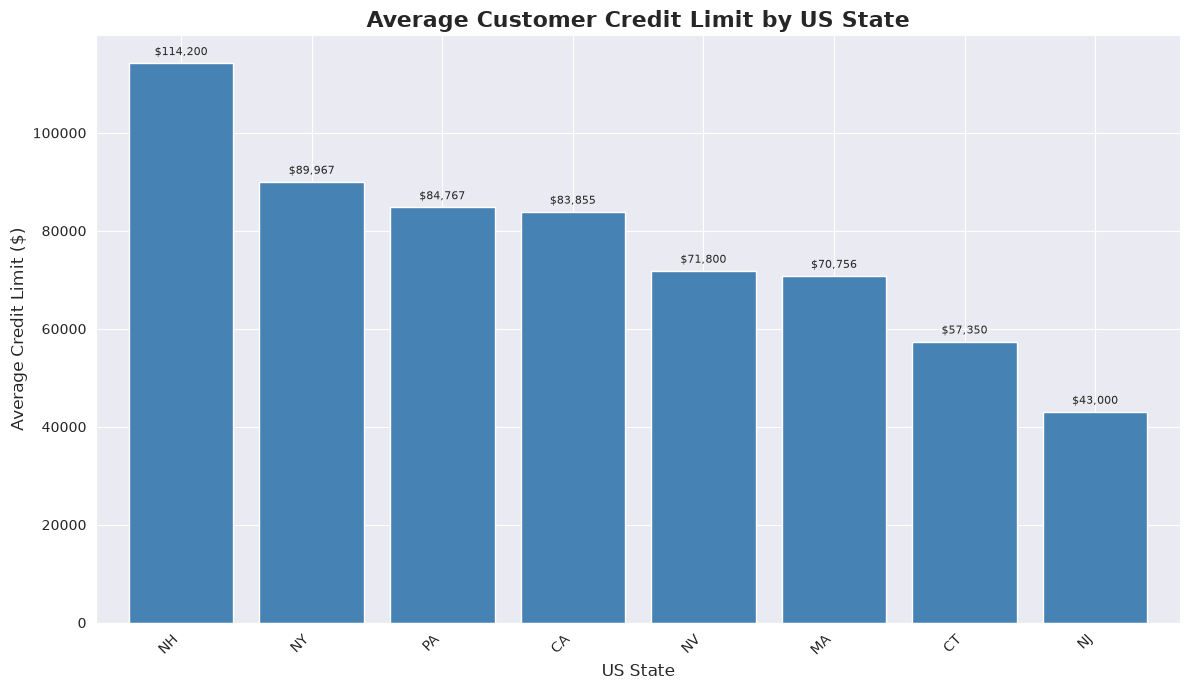

In [35]:
# Replace None with your visual code
#setting the style
sns.set_style("darkgrid")
# Sort states by average credit limit
state_credit = state_credit.sort_values(
    by="avg_creditLimit",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 7))

ax = state_credit.plot(
    x="state",
    y="avg_creditLimit",
    kind="bar",
    color="steelblue",
    legend=False,
    width=0.8,
    figsize=(12, 7)
)

# Add a value label above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"${height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=8
    )

# Improve titles and labels
plt.title(
    "Average Customer Credit Limit by US State",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("US State", fontsize=12)
plt.ylabel("Average Credit Limit ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [36]:
# Replace None with your code
top_customers = pd.read_sql("""
            SELECT 
                customerNumber,
                customerName,
                SUM(amount) AS total_amount
            FROM customers
            JOIN payments
                USING(customerNumber)
            GROUP BY customerName
            ORDER BY total_amount DESC
            LIMIT 10;""", conn)
top_customers

,customerNumber,customerName,total_amount
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

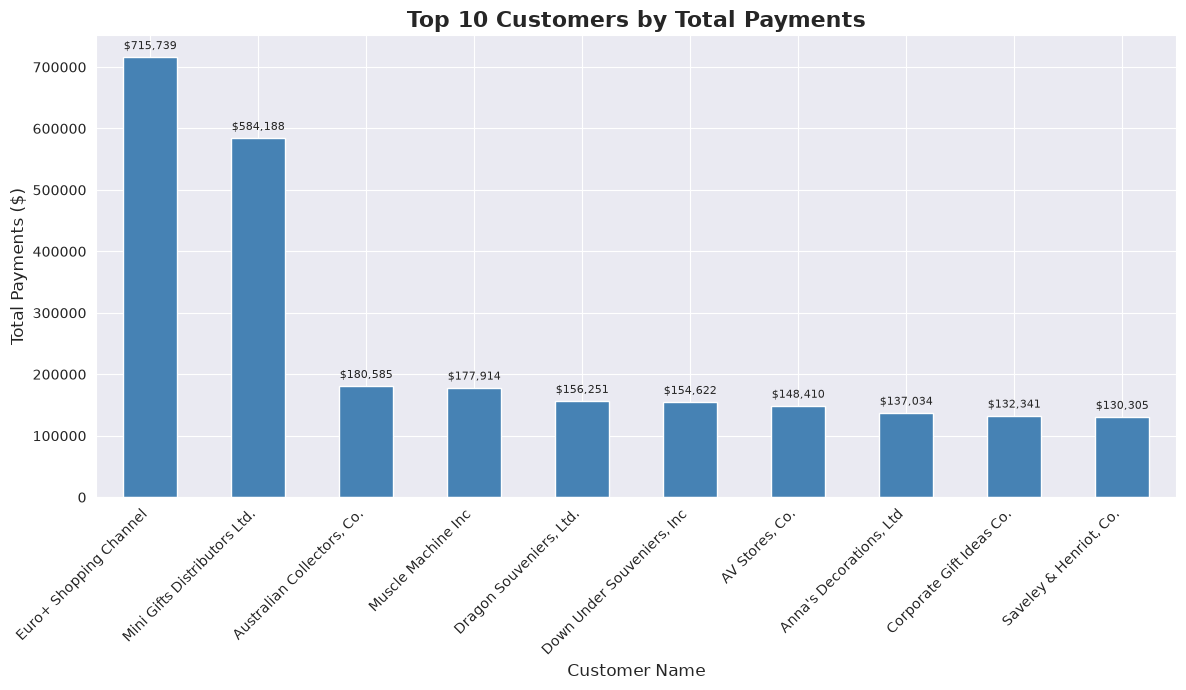

In [ ]:
#setting the style
sns.set_style("darkgrid")
# Sort customers from highest to lowest payments
top_customers = top_customers.sort_values(
    by="total_amount",
    ascending=False
)

# Create the bar chart
ax = top_customers.plot(
    x="customerName",
    y="total_amount",
    kind="bar",
    color="steelblue",
    legend=False,
    figsize=(12, 7)
)

# Annotate each bar with its payment amount
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"${height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=8
    )

# Add title and labels
plt.title("Top 10 Customers by Total Payments", fontsize=16, fontweight="bold")
plt.xlabel("Customer Name", fontsize=12)
plt.ylabel("Total Payments ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [38]:

pd.read_sql("""
    SELECT
        customers.customerName,
        products.productName,
        SUM(orderdetails.quantityOrdered) AS total_quantity
    FROM customers
    JOIN orders
        USING (customerNumber)
    JOIN orderdetails
        USING (orderNumber)
    JOIN products
        USING (productCode)
    GROUP BY customers.customerNumber,
        customers.customerName,
        products.productCode,
        products.productName
    HAVING SUM(orderdetails.quantityOrdered) >= 10
    ORDER BY total_quantity ASC;
""", conn)


,customerName,productName,total_quantity
0,Petit Auto,1913 Ford Model T Speedster,10
1,"Extreme Desk Decorations, Ltd",1961 Chevrolet Impala,10
2,La Rochelle Gifts,1954 Greyhound Scenicruiser,11
3,Tekni Collectables Inc.,American Airlines: B767-300,11
4,The Sharp Gifts Warehouse,1969 Chevrolet Camaro Z28,13
...,...,...,...
2526,Euro+ Shopping Channel,2002 Chevy Corvette,174
2527,Euro+ Shopping Channel,1957 Chevy Pickup,183
2528,Euro+ Shopping Channel,1970 Dodge Coronet,197
2529,Euro+ Shopping Channel,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [39]:
# Replace None with your code
product_line_data = pd.read_sql("""
            SELECT
                products.productLine,
                COUNT(DISTINCT products.productCode) AS total_products,
                SUM(orderDetails.quantityOrdered) AS total_quantity_ordered
            FROM products
            JOIN orderDetails
                USING (productCode)
            GROUP BY products.productLine
            ORDER BY total_quantity_ordered DESC;
""", conn)
product_line_data

,productLine,total_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

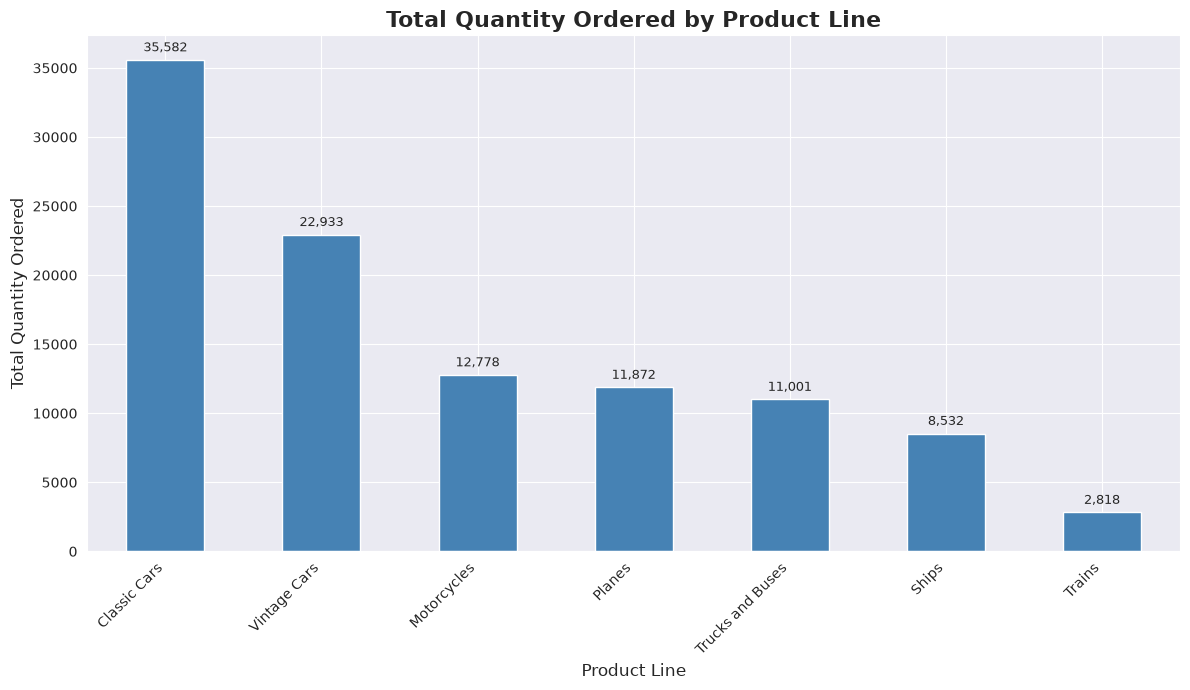

In [40]:
#setting the style
sns.set_style("darkgrid")
# Sort product lines by total quantity ordered
product_line_data = product_line_data.sort_values(
    by="total_quantity_ordered",
    ascending=False
)

# Create the bar chart
ax = product_line_data.plot(
    x="productLine",
    y="total_quantity_ordered",
    kind="bar",
    color="steelblue",
    legend=False,
    figsize=(12, 7)
)

# Annotate each bar with its value
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=9
    )

# Add labels and title
plt.xlabel("Product Line", fontsize=12)
plt.ylabel("Total Quantity Ordered", fontsize=12)
plt.title(
    "Total Quantity Ordered by Product Line",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I chose a bar chart because it makes it easy to compare the total quantity of products ordered across different product lines. Each bar represents a product line, and the height of the bar shows how many units customers ordered. This makes it easy to identify which product lines are most popular and which have lower demand.

In the context of the question, the chart helps the company make better decisions about inventory management, marketing, and product development. Product lines with higher order quantities may need more stock and greater marketing support, while those with lower quantities may need further investigation to understand customer demand. The query also provides the total number of distinct products in each product line, allowing the company to compare product variety with demand and assess whether having more products is associated with higher sales.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [41]:

pd.read_sql("""
    SELECT
        e.employeeNumber,
        e.firstName,
        e.lastName,
        e.jobTitle,
        e.officeCode,
        e.reportsTo,
        s.firstName AS supervisor_firstName,
        s.lastName AS supervisor_lastName,
        s.jobTitle AS supervisor_jobTitle
    FROM employees AS e
    LEFT JOIN employees AS s
        ON e.reportsTo = s.employeeNumber
    WHERE e.officeCode IN (
        SELECT officeCode
        FROM employees
        GROUP BY officeCode
        HAVING COUNT(employeeNumber) < 5
    )
    ORDER BY e.officeCode, e.lastName;
""", conn)


,employeeNumber,firstName,lastName,jobTitle,officeCode,reportsTo,supervisor_firstName,supervisor_lastName,supervisor_jobTitle
0,1188,Julie,Firrelli,Sales Rep,2,1143,Anthony,Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,1143,Anthony,Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,1143,Anthony,Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,1143,Anthony,Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,5,1621,Mami,Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,5,1056,Mary,Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,6,1088,William,Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,6,1088,William,Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,1088,William,Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),6,1056,Mary,Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I used a subquery to identify offices with fewer than five employees before selecting the employees who work in those offices. The subquery groups employees by officeCode and uses HAVING COUNT(employeeNumber) < 5 to filter the groups based on the number of employees. It returns only the office codes that meet this condition.

The main query then uses WHERE e.officeCode IN (...) to select employees whose office codes appear in the subquery results. I also used a self-join on the employees table to retrieve each employee's supervisor details by matching reportsTo with the supervisor's employeeNumber. This ensures that the final result includes employees in small offices, their job titles, and their supervisors, giving management the information needed to plan remote work arrangements.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [42]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [43]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

### Questions to be worked on

1. How many records are in each database table?</br>
Check the row counts of all eight tables, including movie_basics, movie_ratings, directors, persons, and principals.

2. What are the columns and data types in the movie tables?</br>
Examine columns such as movie_id, primary_title, start_year, runtime_minutes, genres, averagerating, and numvotes.

3. How did the number of movies change from 2010 to 2019?</br>
Count movie records for each year and visualize.

4. Which movie genres have the highest average audience ratings?</br>
Calculate average ratings by genre, considering genres with at least 100 rated movie records.

5. How many missing values and possible data-quality issues exist?</br>
Check missing titles, years, runtimes, genres, movie IDs, ratings, and vote counts.

6. Are there duplicate movie IDs or invalid ratings?</br>
Checks for duplicate IDs in movie_basics or movie_ratings, and no missing or out-of-range ratings or invalid vote counts in the ratings table.

7. What data-cleaning tasks should be considered before analysis?</br>
Identify missing runtimes and genres and the need to exclude movies with start_year > 2019. 

### 1. Getting the names of all tables and total number of records in each table

In [44]:
# Get the names of all tables
tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

tables = pd.read_sql_query(tables_query, conn4)

print("Tables in the database:")
display(tables)

# Count the records in each table
for table_name in tables["name"]:
    result = pd.read_sql_query(
        f'SELECT COUNT(*) AS total_rows FROM "{table_name}"',
        conn4
    )
    print(f"{table_name}: {result.iloc[0]['total_rows']} rows")


Tables in the database:


,name
0,directors
1,known_for
2,movie_akas
3,movie_basics
4,movie_ratings
5,persons
6,principals
7,writers


directors: 291174 rows
known_for: 1638260 rows
movie_akas: 331703 rows
movie_basics: 146144 rows
movie_ratings: 73856 rows
persons: 606648 rows
principals: 1028186 rows
writers: 255873 rows


### Two tables of focus are movie_basics and movie_ratings

### 2. Column data types 

In [45]:

# Inspect the structure of the two main tables
for table_name in ["movie_basics", "movie_ratings"]:
    print(f"\n--- {table_name} ---")

    query = f'PRAGMA table_info("{table_name}")'
    display(pd.read_sql_query(query, conn4))



--- movie_basics ---


,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,primary_title,TEXT,0,None,0
2,2,original_title,TEXT,0,None,0
3,3,start_year,INTEGER,0,None,0
4,4,runtime_minutes,REAL,0,None,0
5,5,genres,TEXT,0,None,0



--- movie_ratings ---


,cid,name,type,notnull,dflt_value,pk
0,0,movie_id,TEXT,0,None,0
1,1,averagerating,REAL,0,None,0
2,2,numvotes,INTEGER,0,None,0


### Checking missing values in each column in our tables of focus

In [46]:

# Check missing values in our two main tables

for table_name in ["movie_basics", "movie_ratings"]:
    print(f"\nMissing values in {table_name}:")

    query = f'SELECT * FROM "{table_name}"'
    df = pd.read_sql_query(query, conn4)

    missing = df.isnull().sum()

    display(missing.to_frame(name="missing_values"))



Missing values in movie_basics:


,missing_values
movie_id,0
primary_title,0
original_title,21
start_year,0
runtime_minutes,31739
genres,5408



Missing values in movie_ratings:


,missing_values
movie_id,0
averagerating,0
numvotes,0


### Returning number of movies produced per year between the year 2010 and 2019

### 3. How number of movies changes from 2010 to 2019

In [47]:

query = """
SELECT
    start_year,
    COUNT(*) AS number_of_movies
FROM movie_basics
WHERE start_year IS NOT NULL 
    AND start_year BETWEEN 2010 AND 2019
GROUP BY start_year
ORDER BY start_year;
"""

year_counts = pd.read_sql_query(query, conn4)
display(year_counts)


,start_year,number_of_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


### Visualizing the number of movies produced per year between the year 2010 and 2019

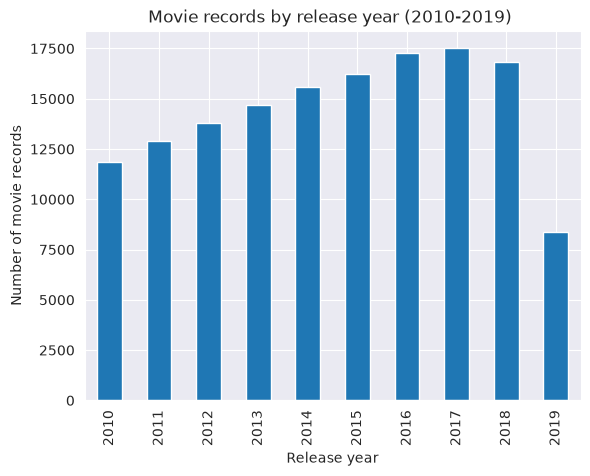

In [48]:
year_counts.plot(
    x = "start_year",
    y = "number_of_movies",
    kind = "bar",
    legend = False
)
plt.xlabel("Release year")
plt.ylabel("Number of movie records")
plt.title("Movie records by release year (2010-2019) ")


plt.show()

### Key findings from data on Movies released each year
- Movie counts increased from 11,849 in 2010 to a peak of 17,504 in 2017.
- The number of movies declined slightly to 16,849 in 2018.
- The count dropped to 8,379 in 2019. This could reflect incomplete coverage of 2019 data, so it should be investigated before drawing conclusions.

### Most common Genres 

In [49]:

query = """
SELECT movie_id, primary_title, start_year, genres
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
  AND genres IS NOT NULL
  AND TRIM(genres) != '';
"""

movies = pd.read_sql_query(query, conn4)

# A movie can belong to multiple genres.
# Split the genres and put each genre on its own row.
genre_data = movies.assign(
    genres=movies["genres"].str.split(",")
).explode("genres")

genre_data["genres"] = genre_data["genres"].str.strip()

# Remove empty genre labels
genre_data = genre_data[
    genre_data["genres"].notna()
    & (genre_data["genres"] != "")
]

genre_counts = (
    genre_data.groupby("genres")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="movie_count")
)

display(genre_counts.head(10))


,genres,movie_count
0,Documentary,51556
1,Drama,49545
2,Comedy,25127
3,Thriller,11746
4,Horror,10692
5,Action,10156
6,Romance,9327
7,Biography,8695
8,Crime,6691
9,Adventure,6366


### Visualization of the most common genres

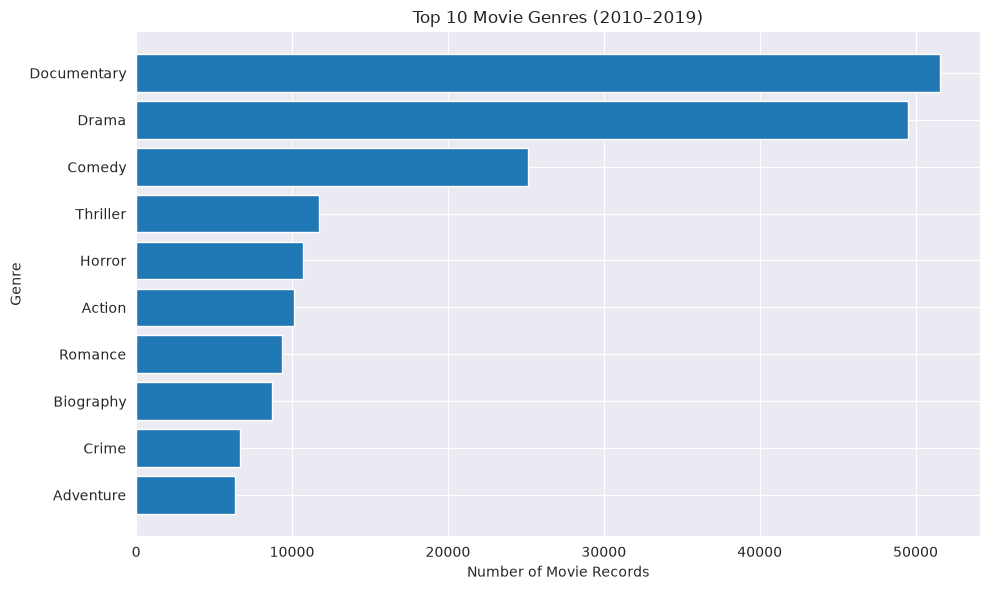

In [50]:

top_genres = genre_counts.head(10).sort_values("movie_count")

plt.figure(figsize=(10, 6))

plt.barh(
    top_genres["genres"],
    top_genres["movie_count"]
)

plt.title("Top 10 Movie Genres (2010–2019)")
plt.xlabel("Number of Movie Records")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()



### 4. Movie genres having the highest average audience ratings?</br>

### Total number of rated movies

In [51]:

query = """
SELECT
    b.movie_id,
    b.start_year,
    b.genres,
    r.averagerating,
    r.numvotes
FROM movie_basics AS b
INNER JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL
  AND TRIM(b.genres) != ''
  AND r.averagerating IS NOT NULL
  AND r.numvotes IS NOT NULL;
"""

rated_movies = pd.read_sql_query(query, conn4)

print("Number of rated movie records:", len(rated_movies))
display(rated_movies.head())


Number of rated movie records: 73052


,movie_id,start_year,genres,averagerating,numvotes
0,tt0063540,2013,"Action,Crime,Drama",7.0,77
1,tt0066787,2019,"Biography,Drama",7.2,43
2,tt0069049,2018,Drama,6.9,4517
3,tt0069204,2018,"Comedy,Drama",6.1,13
4,tt0100275,2017,"Comedy,Drama,Fantasy",6.5,119


### Top rated genres

In [52]:

rated_genres = rated_movies.assign(
    genres=rated_movies["genres"].str.split(",")
).explode("genres")

rated_genres["genres"] = rated_genres["genres"].str.strip()

rated_genres = rated_genres[
    rated_genres["genres"].notna()
    & (rated_genres["genres"] != "")
]

genre_ratings = (
    rated_genres.groupby("genres")
    .agg(
        movie_count=("movie_id", "nunique"),
        average_rating=("averagerating", "mean"),
        total_votes=("numvotes", "sum")
    )
    .reset_index()
)

# Keep genres with at least 100 rated movie records
genre_ratings = genre_ratings[
    genre_ratings["movie_count"] >= 100
]

genre_ratings = genre_ratings.sort_values(
    "average_rating", ascending=False
)

display(genre_ratings.head(10).round(2))


,genres,movie_count,average_rating,total_votes
7,Documentary,17753,7.33,4739345
17,News,579,7.27,123319
4,Biography,3809,7.16,21609446
14,Music,1968,7.09,5453369
12,History,2825,7.04,7843349
22,Sport,1179,6.96,3755824
24,War,853,6.58,2684725
15,Musical,721,6.50,1387965
8,Drama,30788,6.40,119567500
9,Family,3412,6.39,8636710


### Average votes per genre

In [53]:

genre_ratings["average_votes"] = (
    genre_ratings["total_votes"] / genre_ratings["movie_count"]
)

display(
    genre_ratings[
        ["genres", "movie_count", "average_rating",
         "total_votes", "average_votes"]
    ].head(10).round(2)
)


,genres,movie_count,average_rating,total_votes,average_votes
7,Documentary,17753,7.33,4739345,266.96
17,News,579,7.27,123319,212.99
4,Biography,3809,7.16,21609446,5673.26
14,Music,1968,7.09,5453369,2771.02
12,History,2825,7.04,7843349,2776.41
22,Sport,1179,6.96,3755824,3185.60
24,War,853,6.58,2684725,3147.39
15,Musical,721,6.50,1387965,1925.06
8,Drama,30788,6.40,119567500,3883.57
9,Family,3412,6.39,8636710,2531.27


### Identifying the data quality issues in the data set


### 5. How many missing values and possible data-quality issues exist?</br>
Check missing titles, years, runtimes, genres, movie IDs, ratings, and vote counts.

Check for duplicated movie id

In [54]:

# Check potential data quality issues in the main movie table

quality_query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT movie_id) AS unique_movie_ids,
    SUM(CASE WHEN movie_id IS NULL THEN 1 ELSE 0 END)
        AS missing_movie_ids,
    SUM(CASE WHEN primary_title IS NULL THEN 1 ELSE 0 END)
        AS missing_titles,
    SUM(CASE WHEN start_year IS NULL THEN 1 ELSE 0 END)
        AS missing_years,
    SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END)
        AS missing_runtimes,
    SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END)
        AS missing_genres,
    SUM(CASE WHEN start_year > 2019 THEN 1 ELSE 0 END)
        AS years_after_2019
FROM movie_basics;
"""

quality_results = pd.read_sql_query(quality_query, conn4)
display(quality_results)


,total_rows,unique_movie_ids,missing_movie_ids,missing_titles,missing_years,missing_runtimes,missing_genres,years_after_2019
0,146144,146144,0,0,0,31739,5408,1063


In [55]:

ratings_quality_query = """
SELECT
    COUNT(*) AS total_rating_rows,
    COUNT(DISTINCT movie_id) AS unique_movie_ids,
    SUM(CASE WHEN movie_id IS NULL THEN 1 ELSE 0 END)
        AS missing_movie_ids,
    SUM(CASE WHEN averagerating IS NULL THEN 1 ELSE 0 END)
        AS missing_ratings,
    SUM(CASE WHEN numvotes IS NULL THEN 1 ELSE 0 END)
        AS missing_vote_counts,
    SUM(CASE WHEN averagerating < 0
              OR averagerating > 10 THEN 1 ELSE 0 END)
        AS ratings_outside_0_to_10,
    SUM(CASE WHEN numvotes < 0 THEN 1 ELSE 0 END)
        AS negative_vote_counts
FROM movie_ratings;
"""

ratings_quality = pd.read_sql_query(
    ratings_quality_query, conn4
)

display(ratings_quality)


,total_rating_rows,unique_movie_ids,missing_movie_ids,missing_ratings,missing_vote_counts,ratings_outside_0_to_10,negative_vote_counts
0,73856,73856,0,0,0,0,0


In [56]:

period_quality_query = """
SELECT
    COUNT(*) AS total_movies_2010_2019,
    SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END)
        AS missing_runtimes,
    SUM(CASE WHEN genres IS NULL OR TRIM(genres) = ''
        THEN 1 ELSE 0 END) AS missing_genres
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
"""

period_quality = pd.read_sql_query(
    period_quality_query, conn4
)

display(period_quality)


,total_movies_2010_2019,missing_runtimes,missing_genres
0,145081,30765,5359


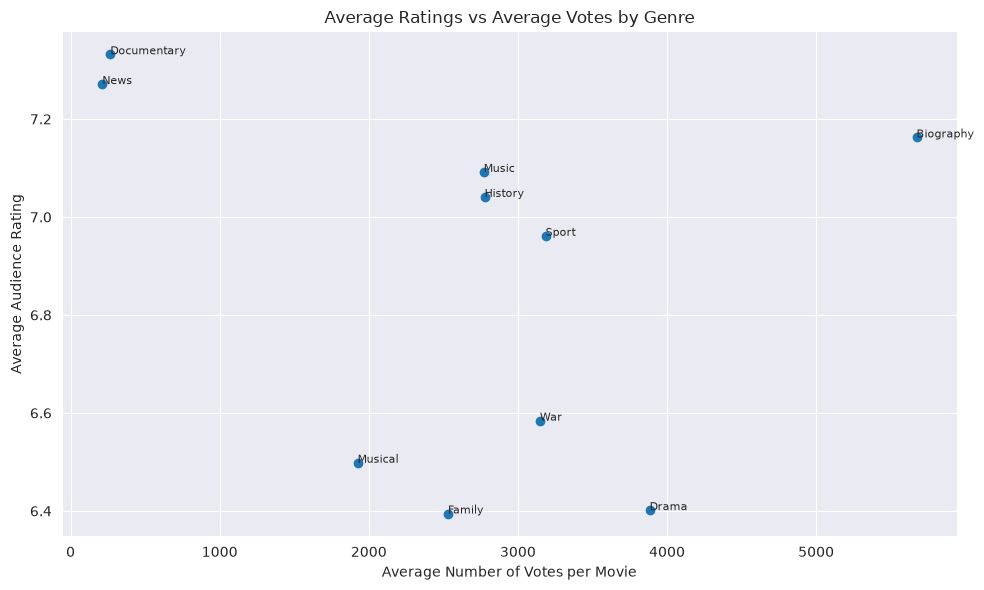

In [57]:

# Add average votes per movie to the existing results
genre_ratings["average_votes"] = (
    genre_ratings["total_votes"] / genre_ratings["movie_count"]
)

# Select the 10 genres with the highest average ratings
top_rated_genres = genre_ratings.nlargest(
    10, "average_rating"
).copy()

# Create a scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    top_rated_genres["average_votes"],
    top_rated_genres["average_rating"]
)

for _, row in top_rated_genres.iterrows():
    plt.annotate(
        row["genres"],
        (row["average_votes"], row["average_rating"]),
        fontsize=8
    )

plt.title("Average Ratings vs Average Votes by Genre")
plt.xlabel("Average Number of Votes per Movie")
plt.ylabel("Average Audience Rating")
plt.tight_layout()
plt.show()


In [58]:
conn4.close()